# Retail Sales Analysis using NumPy, Pandas 
### A Classroom Data Analytics Project  Superstore Dataset

Course Level: Post NumPy & Pandas Fundamentals
Tools: Python, NumPy, Pandas, Matplotlib

In this project, you'll analyze the Superstore dataset (2014–2017) to solve real business problems using Python. Instead of focusing only on syntax, you'll use data analysis to identify profitable products, evaluate regional performance, analyze sales trends, and perform time series analysis to understand business growth.

Topics Covered
Data Loading & Inspection
Data Cleaning
NumPy Analysis
Business Insights (Category, Product, Customer & Region)
Time Series Analysis (Monthly Trends, Resampling, Rolling Average, Growth Rate)
Business Recommendations & Practice Questions

## 1. Setting Up

** Before an analyst opens a single file, they set up their toolkit. We'll do
the same  nothing fancy, just the libraries this whole notebook depends on.

**What are we going to do?** Import Pandas and NumPy.

**Why is this important?** Every line of analysis below depends on these two imports. Doing it
once, at the top, keeps the notebook clean and predictable.

In [3]:
# Write your code here
import numpy as np
import pandas as pd

## 2. Loading the Dataset

 The Superstore's sales team has exported four years of order-level
transactions into a single CSV file, and handed it to you, the analyst, to make sense of.

**What are we going to do?** Read the CSV into a DataFrame using `read_csv()`.

**Why is this important?** Nothing in this project happens until the raw data is sitting in
memory as a DataFrame. We also pass `encoding="latin1"` because Superstore exports commonly
contain characters that break the default UTF-8 reader.

In [4]:
# Write your code here
df = pd.read_csv("D:\Projects\Retail_sales_analysis\Superstore (2).csv")
df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/08/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/08/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,06/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 3. First Look at the Data

 Before trusting any numbers a client will see in a report, an analyst
always checks the shape, structure, and health of the raw data first.

**What are we going to do?** Check `shape`, `columns`, `dtypes`, `info()`, and `describe()`.

**Why is this important?** These five checks answer: *How big is this dataset? What fields do I
have? Are numbers stored as numbers? Are there obvious data quality issues?* Skipping this step is
how analysts end up presenting broken numbers.

In [5]:
# Write your code here
df.shape


(9994, 21)

In [6]:
# Write your code here
df.columns


Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

In [7]:
# Write your code here
df.dtypes

Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

In [8]:
# Write your code here
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9845 non-null   float64
 18  Quantity

## 4. Cleaning the Data

 A client will not trust a report built on a dataset nobody bothered to
clean. Before any analysis, we confirm there are no missing values, no duplicate orders, that
every column is stored as the right type, and that column names are easy to work with.

**What are we going to do?** Run `isnull()`, `fillna()` (as a safety net), `drop_duplicates()`,
`astype()`, and `rename()`.

**Why is this important?** Clean, well-typed, consistently-named columns are what make every
later `groupby`, `loc`, and time series operation reliable instead of fragile.

In [9]:
df.isnull().sum()

Row ID             0
Order ID           0
Order Date         0
Ship Date          0
Ship Mode          0
Customer ID        0
Customer Name      0
Segment            0
Country            0
City               0
State              0
Postal Code        0
Region             0
Product ID         0
Category           0
Sub-Category       0
Product Name       0
Sales            149
Quantity           0
Discount           0
Profit           149
dtype: int64

In [10]:
# Write your code 
df["Sales"] = df["Sales"].fillna(df["Sales"].mean())
df["Profit"] =  df["Profit"].fillna(df["Profit"].mean())


In [11]:
# Write your code here
df.duplicated().sum()

np.int64(0)

In [12]:
# Write your code here
df.drop_duplicates()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/08/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/08/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,06/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,9990,CA-2014-110422,1/21/2014,1/23/2014,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.2480,3,0.20,4.1028
9990,9991,CA-2017-121258,2/26/2017,03/03/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.9600,2,0.00,15.6332
9991,9992,CA-2017-121258,2/26/2017,03/03/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.5760,2,0.20,19.3932
9992,9993,CA-2017-121258,2/26/2017,03/03/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.6000,4,0.00,13.3200


In [13]:
df.head(2)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/08/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136
1,2,CA-2016-152156,11/08/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.0,219.5820


In [14]:
# Write your code here
df["Row ID"] = df["Row ID"].astype(int)
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

In [15]:
# Write your code here
df.dtypes

Row ID                    int64
Order ID                 object
Order Date       datetime64[ns]
Ship Date        datetime64[ns]
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code               int64
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object

## 5. A Quick NumPy Refresher Applied to Real Business Numbers

 Before jumping into Pandas-heavy analysis, let's ground ourselves with the
NumPy concepts you already know, but now applied directly to Superstore numbers instead of toy
arrays.

**What are we going to do?** Use `np.unique()`, `np.sort()`, broadcasting, and NumPy aggregation
functions on Sales, Profit, and Category data.

**Why is this important?** Pandas is built on top of NumPy  every column here *is* a NumPy
array underneath. Seeing that link clearly makes both tools easier to reason about together.

In [16]:
# Write your code her
print(np.unique(df["Region"]))
print(df["Region"].unique())

['Central' 'East' 'South' 'West']
['South' 'West' 'Central' 'East']


In [17]:
# Write your code here
np.sort(df["Profit"] )

array([-6599.978 , -3839.9904, -3701.8928, ...,  4946.37  ,  5039.9856,
        8399.976 ], shape=(9994,))

## 6. Business Question 1  Which Category Generated the Highest Sales?

 The merchandising team wants to know, of Furniture, Office Supplies, and
Technology, which category is actually carrying the business.

**What are we going to do?** Group orders by `Category`, sum their Sales, and sort the result.

**Why is this important?** Category-level revenue is the first cut every retail business reviews
before deciding where to invest in inventory and marketing.

In [18]:
# Write your code here
df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

Category
Technology         825430.372997
Furniture          732943.335697
Office Supplies    732103.179193
Name: Sales, dtype: float64

### Here we know Technology = 825430 which sales is highest.

**Business Insight:** The three categories are much closer in share than most people would
assume — this is a genuinely diversified revenue base, not a single-product business.

## 7. Business Question 2 — Which Sub-Category Generated the Highest Profit?

**Business Scenario:** High sales doesn't always mean high profit. Finance wants to know which
*sub*-category (a more granular cut, like Chairs or Tables within Furniture) actually drops the
most money to the bottom line — and which ones might be quietly losing money.

**What are we going to do?** Group by `Sub_Category`, aggregate Sales and Profit together with
`agg()`, and sort by Profit.

**Why is this important?** Sales and Profit can tell completely different stories at this level
of detail — this is where a business finds its real winners and losers.

In [19]:
# Write your code here
profitable_subcatagory = df.groupby(["Category","Sub-Category"]).agg({"Sales" : sum , "Profit" : sum})
profitable_subcatagory.sort_values("Profit" , ascending=False)

C:\Users\unick\AppData\Local\Temp\ipykernel_13940\4219374449.py:2: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  profitable_subcatagory = df.groupby(["Category","Sub-Category"]).agg({"Sales" : sum , "Profit" : sum})
C:\Users\unick\AppData\Local\Temp\ipykernel_13940\4219374449.py:2: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  profitable_subcatagory = df.groupby(["Category","Sub-Category"]).agg({"Sales" : sum , "Profit" : sum})


Sales        Profit
Category        Sub-Category                             
Technology      Copiers       149528.030000  48926.013618
                Phones        322451.582798  44529.339784
                Accessories   164432.043999  41515.308177
Office Supplies Paper          82414.953198  34285.184269
                Binders       206727.296199  30875.446379
Furniture       Chairs        322572.766599  26644.788092
Office Supplies Storage       224079.376799  21376.492740
                Appliances    108040.313799  18125.962666
Furniture       Furnishings    92489.999199  13183.452177
Office Supplies Envelopes      16675.779200   6919.821755
                Art            29523.647599   6709.351621
                Labels         13263.432800   5612.557855
Technology      Machines      189018.716200   4056.636418
Office Supplies Fasteners       4129.776000   1171.552666
                Supplies       47248.603600  -1167.078782
Furniture       Bookcases     114713.689100  -3458.615363
                Tables        203166.880800 -17780.046826

**Business Insight:** **Copiers and Phones** sit at the top for profit. But scroll to the bottom —
**Tables and Bookcases post a net loss** despite generating real sales. These are prime
candidates for a pricing or discount policy review.

In [20]:
# Write your code here

**Business Insight:** Only a small handful of sub-categories actually dip into negative
territory — a focused fix on just those few could meaningfully lift company-wide profit.

## 8. Business Question 3 — Top 10 Customers by Sales

**Business Scenario:** The account management team wants a VIP list — the customers who have
generated the most revenue over the years, so they can be prioritized for loyalty offers.

**What are we going to do?** Group by `Customer_Name`, sum Sales, sort, and take the top 10.

**Why is this important?** Retaining your highest-value customers is almost always cheaper than
acquiring new ones — you can't protect revenue you can't identify.

In [21]:
# Write your code here
df.groupby("Customer Name")[["Sales","Profit"]].sum().sort_values("Sales",ascending=False).reset_index().head(10)

,Customer Name,Sales,Profit
0,Sean Miller,25043.050,-1786.801782
1,Tamara Chand,19052.218,8981.323900
2,Raymond Buch,15117.339,301.782055
3,Tom Ashbrook,14595.620,4703.788300
4,Adrian Barton,14473.571,5444.805500
5,Ken Lonsdale,14175.229,806.855000
6,Sanjit Chand,14142.334,5757.411900
7,Hunter Lopez,12873.298,5622.429200
8,Sanjit Engle,12209.438,2650.676900
9,Christopher Conant,12129.072,2177.049300


**Business Insight:** The top customer alone has generated well over $10,000 in lifetime sales.
These 10 names are the retail equivalent of a VIP list — worth a dedicated account manager, not a
generic email blast.

## 9. Business Question 4 — Top 10 Products by Profit

**Business Scenario:** Inventory planning wants to know exactly which individual products to keep
stocked heavily going into next year.

**What are we going to do?** Group by `Product_Name`, sum Profit, sort descending, and take the
top 10.

**Why is this important?** Category-level insight (Section 7) tells us *where* to look;
product-level insight tells us *exactly what* to reorder.

In [22]:
# Write your code here
df.groupby("Product Name")["Profit"].sum().reset_index().sort_values("Profit",ascending=False).head(10)

,Product Name,Profit
404,Canon imageCLASS 2200 Advanced Copier,18508.116718
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,7753.039000
805,Hewlett Packard LaserJet 3310 Copier,6983.883600
400,Canon PC1060 Personal Laser Copier,4570.934700
787,HP Designjet T520 Inkjet Large Format Printer ...,4094.976600
165,Ativa V4110MDD Micro-Cut Shredder,3772.946100
19,"3D Systems Cube Printer, 2nd Generation, Magenta",3717.971400
1276,Plantronics Savi W720 Multi-Device Wireless He...,3696.282000
895,Ibico EPK-21 Electric Binding System,3345.282300
1840,Zebra ZM400 Thermal Label Printer,3343.536000


**Business Insight:** A single Canon copier is the single most profitable product in the entire
four-year history — a reminder that one hero SKU can matter more than an entire sub-category of
smaller items.

## 10. Business Question 5 — Which State Generated the Highest Revenue?

**Business Scenario:** The expansion team is deciding where to open the next physical showroom,
and wants to see revenue broken down by state.

**What are we going to do?** Group by `State`, sum Sales, and sort.

**Why is this important?** Geographic concentration tells a business where its customer base
actually is — critical for logistics, marketing spend, and expansion decisions.

In [23]:
# Write your code here
df.groupby("State")["Sales"].sum().reset_index().sort_values("Sales",ascending=False).head(10)


,State,Sales
3,California,455943.688698
30,New York,308983.022598
41,Texas,170815.134999
45,Washington,139109.209199
36,Pennsylvania,117029.904399
8,Florida,88764.309599
11,Illinois,80151.536600
33,Ohio,79321.734000
20,Michigan,76368.184800
44,Virginia,67799.735600


**Business Insight:** **California and New York** dominate state-level revenue by a wide margin
over every other state — unsurprising given their population, but it confirms coastal markets
are the backbone of this business.

## 11. Business Question 6 — Which Region Is the Most Profitable?

**Business Scenario:** Regional VPs are reviewed quarterly on profit, not just sales. Leadership
wants a clean region-by-category profit breakdown for that review.

**What are we going to do?** Build a `pivot_table()` of average and total Profit, sliced by
Region and Category at once.

**Why is this important?** A pivot table answers a two-dimensional business question ("which
region *and* which category?") in a single readable view — exactly the shape a business review
deck needs.

In [24]:
pivot = df.pivot_table(values='Profit',aggfunc='sum', index= "Region" , columns= "Category")
pivot

Category,Furniture,Office Supplies,Technology
Region,,,
Central,-2795.112845,9613.135353,33685.555092
East,3039.230429,41790.516624,47982.669647
South,6784.715655,20321.921250,20054.716255
West,11560.744840,52183.717942,37304.357003


**Business Insight:** The **West region is the most profitable overall**, and Technology is the
strongest category in nearly every region — while Furniture drags down profit in more than one
region, echoing what we saw with Tables and Bookcases earlier.

## 12. Business Question 7 — Average Shipping Days

**Business Scenario:** Operations wants to know how many days, on average, pass between an order
being placed and it being shipped — a key customer-experience metric.

**What are we going to do?** Subtract `Order_Date` from `Ship_Date` using `apply()` and a
`lambda`, then average the result.

**Why is this important?** Shipping speed is one of the most direct levers a retailer has over
customer satisfaction — and it's simple to compute once both columns are true datetimes.

In [28]:
shipping_days = df.apply(lambda row: row['Ship Date'] - row['Order Date'], axis=1)
average_shipping_time = shipping_days.mean()
print(average_shipping_time)

3 days 22:59:46.311787072


**Business Insight:** Shipping times vary order to order, but average out to just under 4 days —
a reasonable benchmark for operations to defend, or try to beat, next quarter.

## 13. Time Series Analysis — Setting the Foundation

**Business Scenario:** So far we've sliced the business by category, customer, product, and
region — all static cuts. But leadership's biggest question is usually simpler: **"Is the
business growing?"** That question can only be answered by looking at the data *over time*.

**What are we going to do?** Set `Order_Date` as the DataFrame's index, and sort the data
chronologically — the two prerequisites for every time series operation that follows.

**Why is this important?** Pandas' powerful time series tools (`resample`, rolling windows,
`pct_change`) all expect a `DatetimeIndex`. This is the single most important setup step in the
entire notebook.

In [30]:
df

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,9990,CA-2014-110422,2014-01-21,2014-01-23,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.2480,3,0.20,4.1028
9990,9991,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.9600,2,0.00,15.6332
9991,9992,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.5760,2,0.20,19.3932
9992,9993,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.6000,4,0.00,13.3200


In [31]:
# Write your code here
df = df.set_index('Order Date')

**Business Insight:** The index confirms our data spans **January 2014 through December 2017** —
four full years, exactly what we need for meaningful monthly, quarterly, and yearly trend
analysis.

In [32]:
df = df.sort_index()

## 14. Business Question 8 — Monthly Sales Trend

**Business Scenario:** The CFO's monthly board deck always starts with one table: total revenue,
month by month.

**What are we going to do?** `resample("ME")` the Sales column to monthly totals.

**Why is this important?** Monthly resampling is the workhorse of retail time series analysis —
it smooths day-to-day noise into a trend a business can actually act on.

<Axes: xlabel='Order Date'>

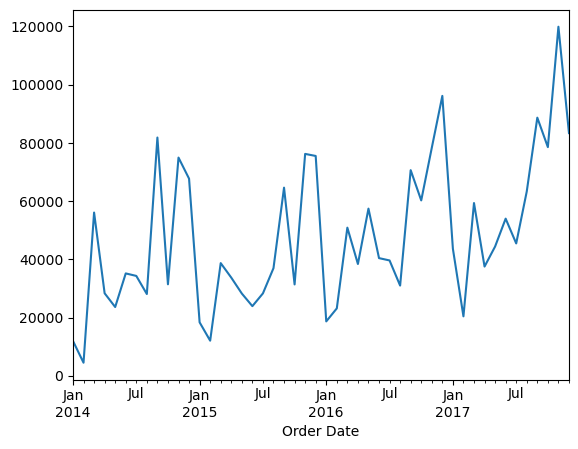

In [33]:
# Write your code here
import seaborn as sns
monthly_sales = df['Sales'].resample('ME').sum()
monthly_sales.plot()

**Business Insight:** A clear seasonal pattern emerges in the numbers — **sales spike every
November/December** (holiday shopping) and dip in early months. Revenue also trends visibly
upward year over year, not just seasonally.

## 15. Business Question 9 — Monthly Profit Trend

**Business Scenario:** Sales going up is good news; but the board wants to know if **profit** is
keeping pace, or if the business is simply buying revenue with deeper discounts.

**What are we going to do?** Resample Profit to monthly totals, exactly like we did for Sales.

**Why is this important?** Comparing the Sales trend and Profit trend side by side is how you
catch a business that's growing revenue while quietly bleeding margin.

<Axes: xlabel='Order Date'>

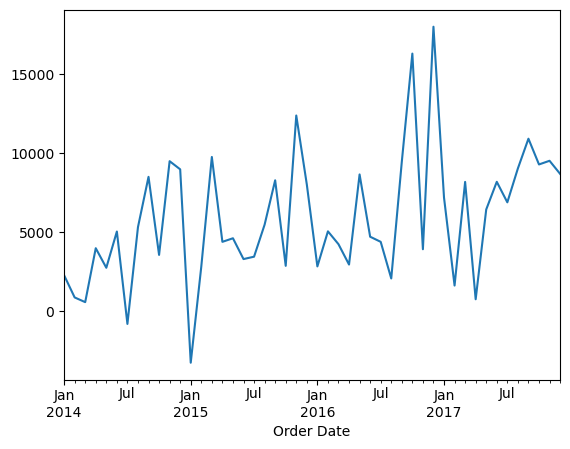

In [34]:
# Write your code here
import seaborn as sns
monthly_sales = df["Profit"].resample('ME').sum()
monthly_sales.plot()

**Business Insight:** Profit follows the same seasonal shape as Sales — but is far more volatile,
and **dips below zero in a few months**. Growing revenue does not automatically mean growing
profit; discounting and product mix both matter.

## 16. Business Questions 10 & 11 — Quarterly and Yearly Sales

**Business Scenario:** Investors don't read monthly numbers — they read quarterly and annual
ones. We need both views ready for the annual report.

**What are we going to do?** Resample Sales to quarterly (`"QE"`) and yearly (`"YE"`) frequency.

**Why is this important?** `resample()` uses the exact same syntax for every frequency — once you
know monthly, quarterly and yearly are free. This is the core "Resampling" concept for this
project.

<Axes: xlabel='Order Date'>

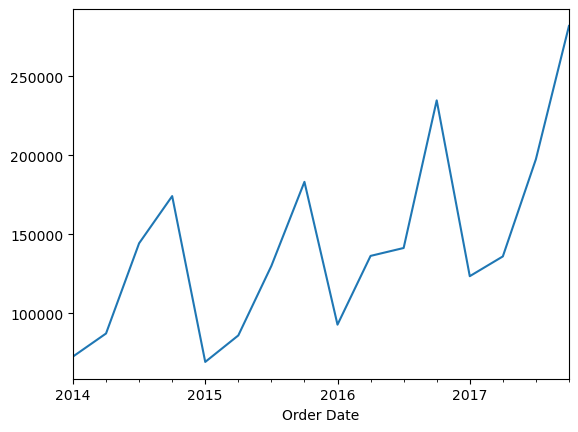

In [35]:
# Write your code here
quarterly = df["Sales"].resample("QE").sum()
quarterly.plot()

**Business Insight:** **Q4 of every single year is the strongest quarter**, confirming the
holiday-season effect is a real, repeating pattern. Sales have also **grown every year from 2014
to 2017** — solid top-line growth across the full history.

<Axes: xlabel='Order Date'>

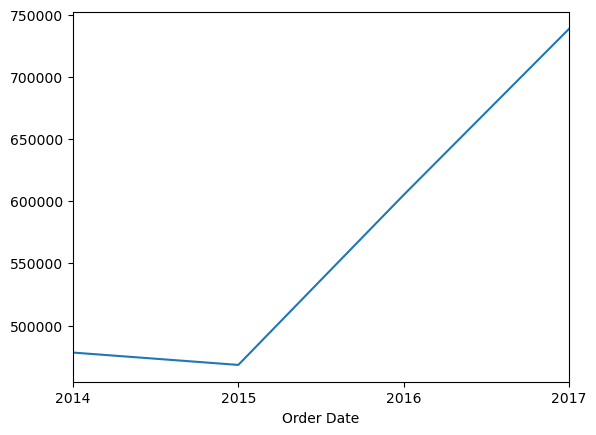

In [36]:
# Write your code here
Yearly_sales = df["Sales"].resample("YE").sum()
Yearly_sales
Yearly_sales.plot()

**Business Insight:** Every year shows positive growth over the year before — confirming the
underlying trend beneath the quarterly seasonality is genuinely upward, not just a seasonal
illusion.

## 17. Business Questions 12 & 13 — Best and Worst Sales Months

**Business Scenario:** Marketing wants to know exactly which month to study for "what worked,"
and which month to study for "what went wrong."

**What are we going to do?** Use `sort_values()` on our `monthly_sales` Series to find the single
highest and lowest month.

**Why is this important?** Extremes are where the clearest business lessons live — the best month
shows you what peak demand looks like; the worst shows you the floor.

In [38]:
# Write your code here
Best_months  = df["Sales"].resample("ME").sum()
Best_months.sort_values(ascending=False).head()



Order Date
2017-11-30    119906.155799
2016-12-31     96152.913000
2017-09-30     88678.540800
2017-12-31     83378.091999
2014-09-30     81853.014400
Name: Sales, dtype: float64

In [39]:
Best_months.sort_values().head()

Order Date
2014-02-28     4519.8920
2014-01-31    11997.2454
2015-02-28    12089.7142
2015-01-31    18392.8768
2016-01-31    18711.5562
Name: Sales, dtype: float64

**Business Insight:** The best month is, unsurprisingly, a **November or December** — peak
holiday shopping. The worst month falls in **early-year territory (Jan/Feb)** — a natural
post-holiday lull worth planning inventory and cash flow around.

## 18. Business Question 14 — Rolling 30-Day Sales Average

**Business Scenario:** Daily sales are noisy — some days are simply slow because fewer orders
happened to land that day. Operations wants a smoothed signal to track the *underlying* trend day
by day, without the noise.

**What are we going to do?** Resample Sales to daily totals, then apply a 30-day rolling average.

**Why is this important?** A rolling average is the standard technique for smoothing volatile
daily data into a trend that's actually usable for forecasting or dashboards.

In [43]:
# Write your code here

daily = df["Sales"].resample("D").sum()

daily_rolling_avg = daily.rolling(window=30, min_periods=1).mean()
daily_rolling_avg

Order Date
2014-01-03      16.448000
2014-01-04     152.254000
2014-01-05     108.014667
2014-01-06     596.627300
2014-01-07     494.733440
                 ...     
2017-12-26    3124.884400
2017-12-27    3076.863800
2017-12-28    2901.677360
2017-12-29    2976.986133
2017-12-30    2779.269733
Freq: D, Name: Sales, Length: 1458, dtype: float64

<Axes: xlabel='Order Date'>

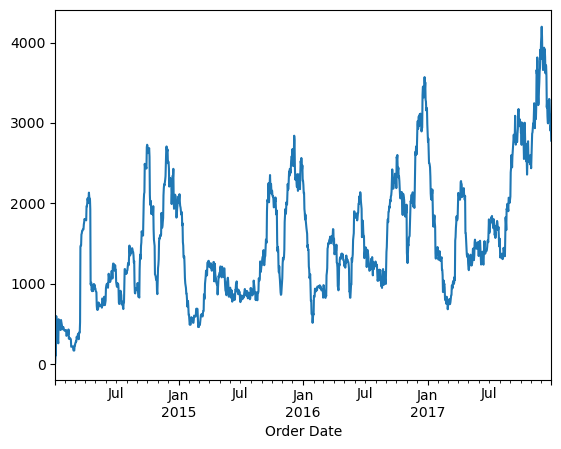

In [44]:
daily_rolling_avg.plot()

**Business Insight:** The rolling average's standard deviation is far lower than daily sales' —
proof that it smooths out day-to-day noise while still tracking the same underlying holiday-season
climb we saw in the monthly numbers, making it the cleanest signal for forecasting or dashboards.

## 19. Business Question 15 — Cumulative Revenue

**Business Scenario:** Finance wants a single running total that shows exactly how much revenue
the business has booked from day one through today — the number investors expect in a growth
story.

**What are we going to do?** Apply `cumsum()` to the monthly sales Series.

**Why is this important?** A cumulative total is the cleanest way to demonstrate sustained growth
— it never goes down, so any slowdown in its pace is instantly visible when compared period to
period.

In [45]:
# Write your code here

daily_sales = df['Sales'].resample('D').sum()
lifetime_revenue = daily_sales.cumsum()
lifetime_revenue


Order Date
2014-01-03    1.644800e+01
2014-01-04    3.045080e+02
2014-01-05    3.240440e+02
2014-01-06    2.386509e+03
2014-01-07    2.473667e+03
                  ...     
2017-12-26    2.285177e+06
2017-12-27    2.285355e+06
2017-12-28    2.287012e+06
2017-12-29    2.289763e+06
2017-12-30    2.290477e+06
Freq: D, Name: Sales, Length: 1458, dtype: float64

**Business Insight:** The final number is the total revenue booked across all four years — the
single top-line figure investors care about most.

## 20. Business Question 16 — Month-over-Month Growth

**Business Scenario:** Absolute sales numbers are useful, but leadership ultimately tracks
**growth rate** — "are we up or down versus last month, and by how much?"

**What are we going to do?** Apply `pct_change()` to the monthly sales Series.

**Why is this important?** `pct_change()` is the standard one-liner for turning any time series
into a growth-rate series — the single most quoted number in any monthly business review.

In [53]:
# Write your code here
df["Sales"].pct_change()*100


Order Date
2014-01-03            NaN
2014-01-04     -28.356031
2014-01-04    2214.460285
2014-01-04     -98.702042
2014-01-05     451.864407
                 ...     
2017-12-30     -98.555184
2017-12-30    1645.238095
2017-12-30      72.294225
2017-12-30     -84.709117
2017-12-30    2224.050633
Name: Sales, Length: 9994, dtype: float64

**Business Insight:** Growth swings wildly — some months post over 50% growth, others show a
sharp decline — confirming this business's revenue is **highly seasonal rather than steadily
growing**, and any single month-over-month number should be read with that context.

## 21. Sales Trend Analysis — Putting It All Together

**Business Scenario:** Leadership doesn't just want tables of numbers — they want the story those
numbers tell, in plain language.

**What are we going to do?** Summarize everything the time series section has shown us.

**Why is this important?** Numbers only become insight once someone translates them into a
decision. This is that translation.

**Business Insight — Sales Trend Summary:**

- Revenue is **strongly seasonal**, peaking every Q4 (Nov/Dec) and dipping every Jan/Feb.
- Despite the seasonality, **yearly totals have grown every year from 2014 to 2017**.
- The 30-day rolling average confirms this growth is a real underlying trend, not noise from a
  few lucky days.
- Month-over-month growth is volatile enough that no single month should be judged in isolation —
  always compare a month to the *same month* in a prior year, not just the month before it.

## 22. Business Question 17 — High Profit vs Low Profit Orders (np.where)

**Business Scenario:** Finance wants every order line tagged as either a "High Profit" or "Low
Profit" order, so they can quickly filter and audit the low-profit ones for discount abuse.

**What are we going to do?** Use `np.where()` to create a new label column based on a Profit
threshold, then use boolean indexing and `query()` to inspect each group.

In [72]:
# Write your code 
df["Profit status by mean"] = np.where(df["Profit"]>df["Profit"].mean() , "High" , "Low")
df["Profit status by mean"].value_counts()

Profit status by mean
Low     7455
High    2539
Name: count, dtype: int64

In [73]:
# Write your code 
df["Profit status by median"] = np.where(df["Profit"]>df["Profit"].median() , "High" , "Low")
df["Profit status by median"].value_counts()

Profit status by median
Low     4997
High    4997
Name: count, dtype: int64

**Business Insight:** A meaningful share of the lowest-profit orders were also **discounted 30% or
more** — strong evidence that overly aggressive discounting, not just cost or price, is a direct
driver of the company's unprofitable orders.

## 23. A Closer Look — loc & iloc in Practice

**Business Scenario:** An executive asks, mid-meeting, to see the full record for the single
highest-profit order, and separately, to see a specific slice of raw rows from the file.

**What are we going to do?** Use `loc` to fetch a row by a label/condition, and `iloc` to fetch
rows by raw position.

In [101]:
#By condition
df.loc[df["Profit"].idxmax()]
df.loc[df["Row ID"] == 6827]

,Row ID,Order ID,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Profit status,Profit status by median,Profit status by mean
Order Date,,,,,,,,,,,,,,,,,,,,,
2016-10-02,6827,CA-2016-118689,2016-10-09,Standard Class,TC-20980,Tamara Chand,Corporate,United States,Lafayette,Indiana,...,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,17499.95,5,0.0,8399.976,High,High,High


In [102]:
df

,Row ID,Order ID,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Profit status,Profit status by median,Profit status by mean
Order Date,,,,,,,,,,,,,,,,,,,,,
2014-01-03,7981,CA-2014-103800,2014-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,Texas,...,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,Low,Low,Low
2014-01-04,740,CA-2014-112326,2014-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,...,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717,Low,Low,Low
2014-01-04,741,CA-2014-112326,2014-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,...,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,Low,Low,Low
2014-01-04,742,CA-2014-112326,2014-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,...,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,Low,Low,Low
2014-01-05,1760,CA-2014-141817,2014-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,Pennsylvania,...,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840,Low,Low,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2017-12-30,5092,CA-2017-156720,2018-01-03,Standard Class,JM-15580,Jill Matthias,Consumer,United States,Loveland,Colorado,...,Office Supplies,Fasteners,Bagged Rubber Bands,3.024,3,0.2,-0.6048,Low,Low,Low
2017-12-30,909,CA-2017-143259,2018-01-03,Standard Class,PO-18865,Patrick O'Donnell,Consumer,United States,New York City,New York,...,Office Supplies,Binders,Wilson Jones Legal Size Ring Binders,52.776,3,0.2,19.7910,Low,High,Low
2017-12-30,908,CA-2017-143259,2018-01-03,Standard Class,PO-18865,Patrick O'Donnell,Consumer,United States,New York City,New York,...,Technology,Phones,Gear Head AU3700S Headset,90.930,7,0.0,2.7279,Low,Low,Low


**Business Insight:** `loc` is how you pull up "the best order we've ever had" whenever
leadership asks; `iloc` is how you pull up "just show me a few raw rows" for a quick sanity
check.

## 24. Business Question 18 — Final Business Recommendations

Based on everything above, here is what we would tell Superstore's leadership team:

1. **Protect Q4.** Holiday-season demand (Nov/Dec) is the single biggest revenue driver every
   year — inventory and staffing plans should be built around it, not treated as a surprise.
2. **Review the discount policy on Furniture**, especially Tables and Bookcases — they generate
   real sales but post a net loss, most likely from over-discounting.
3. **Double down on Technology**, the strongest category for both sales and profit, and on the
   West region, the most profitable overall.
4. **Investigate orders discounted 30%+**, since they disproportionately show up among the
   lowest-profit orders in the business.
5. **Build a retention program around the top 10 customers** — they represent an outsized and
   easily identifiable share of lifetime revenue.

## 25. Final Summary

Over the course of this project we took a raw, four-year CSV export from a US retail chain and
turned it into a full business narrative:

- We **loaded and cleaned** the data — confirming its integrity, fixing types, and renaming
  columns for usability.
- We used **NumPy** directly on business arrays for uniqueness, sorting, broadcasting, and
  aggregation.
- We answered concrete **business questions** about category, sub-category, customer, product,
  state, and region performance using `groupby`, `agg`, and `pivot_table`.
- We built a full **time series pipeline**: datetime conversion, indexing, sorting, monthly /
  quarterly / yearly resampling, rolling averages, cumulative revenue, and month-over-month growth.
- We closed by combining `np.where()`, boolean indexing, and `query()` to flag and investigate
  unprofitable orders — turning analysis into an actionable recommendation.

This is exactly the workflow a retail analyst runs every single reporting cycle — you now have a
template you can point at any transaction-level dataset.

## 26. Ten Business Insights

1. Technology, Furniture, and Office Supplies contribute fairly evenly to total sales — this is a
   diversified business, not a single-category one.
2. Copiers and Phones are the most profitable sub-categories; Tables and Bookcases post a net
   loss.
3. A small group of top customers account for a disproportionate share of lifetime revenue.
4. A single hero product (a Canon copier) is the most profitable individual product in company
   history.
5. California and New York are the company's two largest state markets by a wide margin.
6. The West region is the most profitable overall; Furniture drags profit down in more than one
   region.
7. Average shipping time sits just under 4 days company-wide.
8. Sales are strongly seasonal, peaking every Q4 and dipping every Jan/Feb — a pattern that
   repeats every single year in the dataset.
9. Yearly revenue has grown every year from 2014 to 2017, even though month-to-month growth is
   volatile.
10. Orders discounted 30% or more are disproportionately represented among the lowest-profit
    orders — discounting policy is a direct, fixable lever on profit.